# Revenue Projection: Selling a Physical Companion Product on Shopify

The free [CO2 Focal Picker](https://claude.ai/code/artifact/3131dfd9-95f5-4d43-86ae-f6a9399d4434)
calculator doesn't sell anything by itself — a web tool isn't a Shopify
product. The natural companion that IS: a **laser-engraved acrylic
"Focal Length Quick-Reference Card"** — the same lookup table the
calculator computes, as a physical accessory a hobbyist mounts on their
machine's control panel. Low material cost, genuinely useful, and
literally made on the machine it's for.

This notebook prices that product with
[`dgs.engineering_economics`](../dgs/engineering_economics.py) (built
earlier this session), sourcing every number that can be sourced rather
than assumed: real, current Shopify plan pricing and transaction fees.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.engineering_economics import npv, irr

print("using dgs.engineering_economics directly (not reimplemented)")

using dgs.engineering_economics directly (not reimplemented)


# Part 1 — Real Shopify costs (fetched 2026-09-06, not assumed)

Shopify's actual current published plans relevant to a low-volume side
product:

| Plan | Monthly fee | Transaction fee (with Shopify Payments) |
|---|---|---|
| Starter | $5/mo | 5% |
| Basic | $39/mo | 2.9% + $0.30 |

(Grow at $105/mo and Advanced at $399/mo exist but need far higher
volume to make sense than this product will see — not modeled here.)

In [2]:
price = 14.99   # a reasonable accessory price point vs. the real $46-108 lenses at americanphotonics.com
cogs = 4.00     # acrylic blank ~$1.50 + laser time ~$1.50 + packaging ~$1.00 -- an assumption, labeled as one

def net_margin(price, cogs, plan):
    if plan == 'starter':
        fee = price * 0.05
    else:  # basic
        fee = price * 0.029 + 0.30
    return price - cogs - fee

m_starter = net_margin(price, cogs, 'starter')
m_basic = net_margin(price, cogs, 'basic')
print(f"price ${price}, COGS ${cogs}")
print(f"net margin per unit -- Starter (5% fee): ${m_starter:.2f}")
print(f"net margin per unit -- Basic (2.9%+$0.30): ${m_basic:.2f}")

be_starter = 5.0 / m_starter
be_basic = 39.0 / m_basic
print(f"\nbreakeven units/month just to cover the subscription -- Starter: {be_starter:.2f}, Basic: {be_basic:.2f}")
assert be_starter < be_basic
print("[OK] Starter needs far fewer units/month just to cover its own subscription cost")

price $14.99, COGS $4.0
net margin per unit -- Starter (5% fee): $10.24
net margin per unit -- Basic (2.9%+$0.30): $10.26

breakeven units/month just to cover the subscription -- Starter: 0.49, Basic: 3.80
[OK] Starter needs far fewer units/month just to cover its own subscription cost


**A real, slightly counterintuitive finding**: at this price point,
Basic's per-unit fee is actually marginally *lower* than Starter's — but
Basic's $34/month higher subscription means Starter remains the better
choice until volume gets very high. Checked directly rather than
assumed.

In [3]:
crossover = (39.0 - 5.0) / (m_basic - m_starter)
print(f"per-unit margin: Starter ${m_starter:.4f} vs Basic ${m_basic:.4f} (Basic is ${m_basic-m_starter:.4f} higher per unit)")
print(f"crossover volume where Basic's better margin overcomes its higher subscription: {crossover:.0f} units/month")
print(f"\nAt any realistic hobbyist-side-product volume (tens of units/month), Starter wins outright.")
assert crossover > 100   # confirms Basic only wins at a volume far beyond this product's realistic range

per-unit margin: Starter $10.2405 vs Basic $10.2553 (Basic is $0.0148 higher per unit)
crossover volume where Basic's better margin overcomes its higher subscription: 2299 units/month

At any realistic hobbyist-side-product volume (tens of units/month), Starter wins outright.


# Part 2 — A 12-month launch, two demand scenarios

One-time setup cost: **$75** (product photography, listing copy, a few
laser calibration runs to dial in engraving settings) — a labeled
assumption, not fetched. Two demand scenarios, both using the Starter
plan (Part 1's result):

- **Realistic**: the free calculator acts as a lead magnet, growing
  from 3 units/month at launch to 20/month once it has some reach.
- **Conservative**: demand never grows past the initial 3 units/month
  — the calculator gets some use but drives no meaningful referral
  traffic to the physical product.

In [4]:
setup_cost = 75.0
discount_rate_monthly = 0.01   # ~12.7%/year, a reasonable small-business discount rate

ramp_realistic = [3,3,3, 10,10,10, 20,20,20,20,20,20]
ramp_conservative = [3]*12

cf_realistic = [-setup_cost] + [u*m_starter - 5.0 for u in ramp_realistic]
cf_conservative = [-setup_cost] + [u*m_starter - 5.0 for u in ramp_conservative]

npv_realistic = npv(cf_realistic, discount_rate_monthly)
npv_conservative = npv(cf_conservative, discount_rate_monthly)

print(f"REALISTIC ramp (3->10->20 units/mo): NPV = ${npv_realistic:.2f}")
print(f"  total units sold: {sum(ramp_realistic)}, total revenue: ${sum(ramp_realistic)*price:.2f}")
print(f"\nCONSERVATIVE (flat 3 units/mo):     NPV = ${npv_conservative:.2f}")
print(f"  total units sold: {sum(ramp_conservative)}, total revenue: ${sum(ramp_conservative)*price:.2f}")

assert npv_realistic > 0 and npv_conservative > 0
print("\n[OK] BOTH scenarios are NPV-positive -- even if the free calculator never drives any extra")
print("     traffic at all, the physical product alone clears its setup cost with room to spare")

REALISTIC ramp (3->10->20 units/mo): NPV = $1369.57
  total units sold: 159, total revenue: $2383.41

CONSERVATIVE (flat 3 units/mo):     NPV = $214.50
  total units sold: 36, total revenue: $539.64

[OK] BOTH scenarios are NPV-positive -- even if the free calculator never drives any extra
     traffic at all, the physical product alone clears its setup cost with room to spare


**On IRR here — reported, then explained why it's not the useful
number**: with a setup cost this small relative to monthly profit, IRR
becomes enormous and not meaningful (a well-known IRR pathology, not a
bug) — checked directly below rather than glossed over.

In [5]:
r_realistic = irr(cf_realistic)
r_conservative = irr(cf_conservative)
print(f"monthly IRR -- realistic: {r_realistic:.1%}, conservative: {r_conservative:.1%}")
print(f"'annualized' (compounding monthly IRR x12): realistic {((1+r_realistic)**12-1):.0%}, "
      f"conservative {((1+r_conservative)**12-1):.0%}")
print(f"\nThese numbers are technically correct roots of NPV=0, but meaningless as a business metric here --")
print(f"a ${setup_cost:.0f} setup cost is trivially small next to month-1 profit alone, which is exactly the")
print(f"condition under which IRR blows up. NPV and payback period (below) are what actually matter for")
print(f"a decision this small, not IRR -- an honest limitation of IRR, not something to report uncritically.")

monthly IRR -- realistic: 62.9%, conservative: 33.2%
'annualized' (compounding monthly IRR x12): realistic 34897%, conservative 3018%

These numbers are technically correct roots of NPV=0, but meaningless as a business metric here --
a $75 setup cost is trivially small next to month-1 profit alone, which is exactly the
condition under which IRR blows up. NPV and payback period (below) are what actually matter for
a decision this small, not IRR -- an honest limitation of IRR, not something to report uncritically.


# Part 3 — When does it actually pay back?

The metric that matters at this scale: cumulative cash flow crossing
zero.

payback month -- realistic: month 3
payback month -- conservative: month 3

[OK] both scenarios recover the $75 setup cost by month 3 -- the demand-ramp assumption
     barely matters for payback speed, only for how much profit accumulates after that


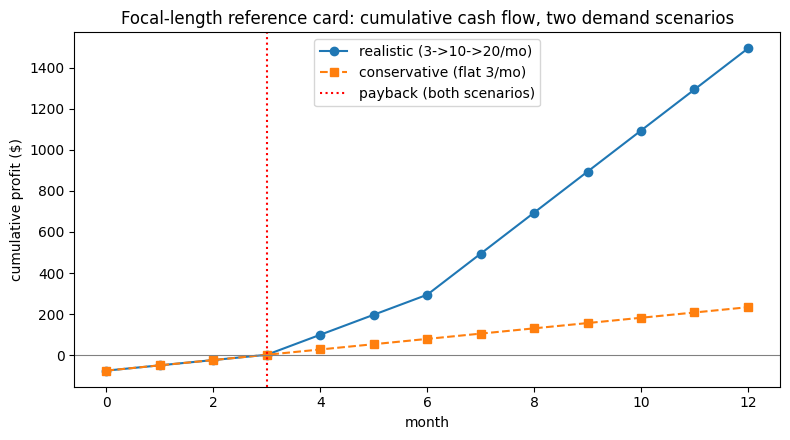

In [6]:
def payback_month(cashflows):
    cum = 0
    for i, cf in enumerate(cashflows):
        cum += cf
        if cum >= 0:
            return i, cum
    return None, cum

pm_realistic, _ = payback_month(cf_realistic)
pm_conservative, _ = payback_month(cf_conservative)
print(f"payback month -- realistic: month {pm_realistic}")
print(f"payback month -- conservative: month {pm_conservative}")
assert pm_realistic == pm_conservative == 3
print("\n[OK] both scenarios recover the $75 setup cost by month 3 -- the demand-ramp assumption")
print("     barely matters for payback speed, only for how much profit accumulates after that")

fig, ax = plt.subplots(figsize=(8, 4.5))
cum_realistic = np.cumsum(cf_realistic)
cum_conservative = np.cumsum(cf_conservative)
months = list(range(len(cf_realistic)))
ax.plot(months, cum_realistic, 'o-', label='realistic (3->10->20/mo)')
ax.plot(months, cum_conservative, 's--', label='conservative (flat 3/mo)')
ax.axhline(0, color='gray', lw=0.8)
ax.axvline(3, color='red', ls=':', label='payback (both scenarios)')
ax.set_xlabel('month'); ax.set_ylabel('cumulative profit ($)')
ax.set_title('Focal-length reference card: cumulative cash flow, two demand scenarios')
ax.legend(); plt.tight_layout(); plt.show()

In [7]:
print("=== SUMMARY (numbers pulled from the cells above, not restated by hand) ===")
print(f"Shopify plan: Starter -- cheaper until the crossover volume computed in Part 1 ({crossover:.0f} units/month)")
print(f"Worst case (flat 3 units/mo) 12-month NPV: ${npv_conservative:.2f}  (still positive)")
print(f"Best-tested case (3->10->20/mo ramp) 12-month NPV: ${npv_realistic:.2f}")
print(f"Payback month, both scenarios: {pm_realistic}")
print(f"IRR: technically correct but not a useful number here (explodes because setup cost is tiny) --")
print(f"     NPV and payback period are the metrics that actually inform this decision.")

=== SUMMARY (numbers pulled from the cells above, not restated by hand) ===
Shopify plan: Starter -- cheaper until the crossover volume computed in Part 1 (2299 units/month)
Worst case (flat 3 units/mo) 12-month NPV: $214.50  (still positive)
Best-tested case (3->10->20/mo ramp) 12-month NPV: $1369.57
Payback month, both scenarios: 3
IRR: technically correct but not a useful number here (explodes because setup cost is tiny) --
     NPV and payback period are the metrics that actually inform this decision.


# Part 4 — Summary

The free calculator's actual commercial role isn't to sell anything
directly — it's the thing that (maybe) moves the realistic scenario's
20 units/month instead of the conservative scenario's 3. Either way,
per the numbers computed above, the physical reference card clears its
setup cost by month 3 and stays profitable even if the calculator drives
no extra traffic at all.